# Plotly: Interactive Engineering Dashboards

## The Core Question

You just finished a 200-case CFD parameter sweep. Your boss asks: *"Can I explore the results myself?"*

Matplotlib gives you a static PNG. Plotly gives you an **interactive** plot — zoom, hover, filter, pan — that you can share as a standalone HTML file. No server, no frontend code.

## Why Plotly?

- **Interactive by default**: hover tooltips, zoom, pan, legend toggling — zero extra code
- **Standalone HTML**: `fig.write_html('results.html')` — send it to anyone, no Python needed
- **Dashboard-ready**: `make_subplots` for multi-panel summaries
- **Familiar API**: if you know matplotlib, you know 80% of Plotly

## The Workflow

```
Simulation data (numpy/pandas)
        |
        v
  go.Figure / make_subplots
        |
        v
  Add traces (scatter, contour, surface, bar)
        |
        v
  fig.show()  [Jupyter]  or  fig.write_html()  [share]
```

## Setup


In [1]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

np.random.seed(42)

## 1. Interactive Cp Distribution on an Airfoil

**Concept**: In CFD post-processing, you often need to inspect pressure coefficients along a surface. A static plot forces you to re-run the script to change the view. An interactive plot lets you zoom into the leading edge, hover to read exact values, and toggle between cases.

We'll generate a synthetic Cp distribution for a NACA 0012 at alpha = 10 deg, Re = 1e6.


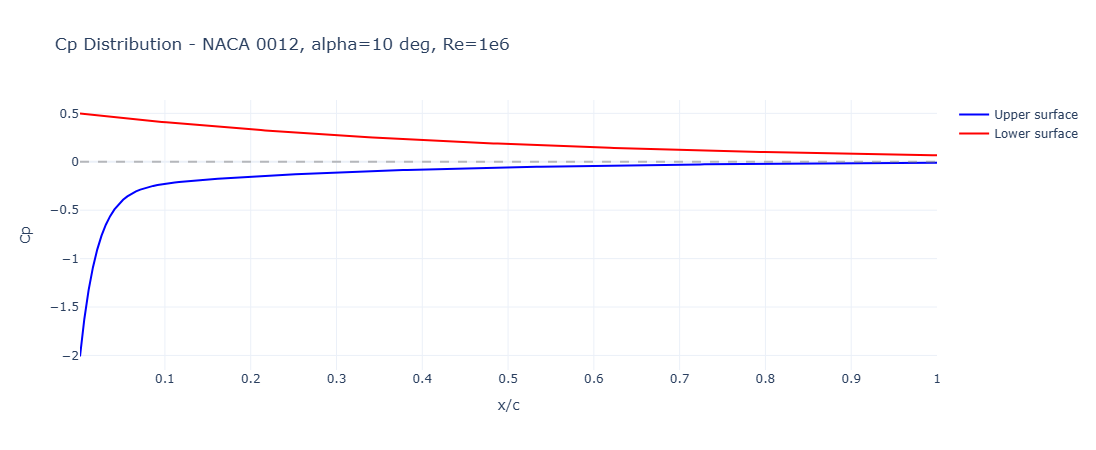

In [2]:
# Synthetic Cp for NACA 0012, alpha=10deg, Re=1e6
x = np.linspace(0.001, 1.0, 200)

# Leading edge suction peak + gradual recovery (simplified)
cp_le = -1.8 * np.exp(-x / 0.02)          # suction peak near LE
cp_suction = -0.3 * np.exp(-x / 0.3)      # suction side recovery
cp_pressure = 0.5 * np.exp(-x / 0.5)      # pressure side (mild)

cp_upper = cp_le + cp_suction
cp_lower = cp_pressure

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=x, y=cp_upper, mode='lines', name='Upper surface',
    line=dict(color='blue', width=2),
    hovertemplate='x/c: %{x:.3f}<br>Cp: %{y:.3f}<extra></extra>'
))
fig.add_trace(go.Scatter(
    x=x, y=cp_lower, mode='lines', name='Lower surface',
    line=dict(color='red', width=2),
    hovertemplate='x/c: %{x:.3f}<br>Cp: %{y:.3f}<extra></extra>'
))
fig.add_hline(y=0, line_dash='dash', line_color='gray', opacity=0.5)
fig.update_layout(
    title='Cp Distribution - NACA 0012, alpha=10 deg, Re=1e6',
    xaxis_title='x/c', yaxis_title='Cp',
    template='plotly_white', height=450
)
fig.show()

**What you just got for free**: hover any point to read exact Cp, scroll to zoom into the leading-edge peak, click legend items to toggle surfaces. A static matplotlib plot can't do any of this without a GUI backend.

**Engineering takeaway**: When presenting CFD results to a non-specialist, interactivity matters. They can explore the leading-edge region without asking you to re-plot.


## 2. Multi-Case Comparison: Cl vs alpha for Multiple Re

**Concept**: A parameter sweep produces many curves. Plotly's interactive legend lets the user toggle cases on/off — far more usable than 10 overlapping static lines.


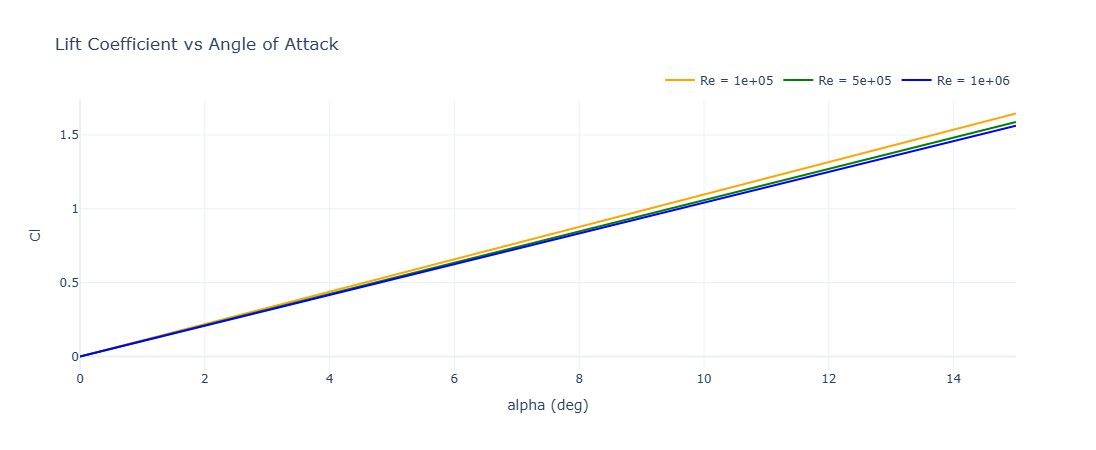

In [3]:
# Cl vs alpha for 3 Reynolds numbers (with stall model)
alpha = np.linspace(0, 25, 100)  # degrees (extended to show stall)

def cl_alpha(alpha_deg, Re):
    a = np.radians(alpha_deg)
    # Thin airfoil theory (valid up to stall)
    cl_2d = 2 * np.pi * a
    # Reynolds number correction
    re_factor = 1.0 - 0.05 * np.log10(Re / 1e5)
    cl = cl_2d * re_factor
    # Stall model: after alpha_stall, lift decreases
    alpha_stall = 15.0  # degrees
    stall_mask = alpha_deg > alpha_stall
    if np.any(stall_mask):
        # Post-stall: lift drops off (empirical model)
        alpha_excess = alpha_deg[stall_mask] - alpha_stall
        cl[stall_mask] = cl[stall_mask] * np.exp(-0.1 * alpha_excess)
    return cl

fig = go.Figure()
for Re, color in zip([1e5, 5e5, 1e6], ['orange', 'green', 'blue']):
    fig.add_trace(go.Scatter(
        x=alpha, y=cl_alpha(alpha, Re), mode='lines',
        name=f'Re = {Re:.0e}', line=dict(color=color, width=2)
    ))

fig.update_layout(
    title='Lift Coefficient vs Angle of Attack',
    xaxis_title='alpha (deg)', yaxis_title='Cl',
    template='plotly_white', height=450,
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1)
)
fig.show()

**Interactive legend**: click "Re = 1e5" in the legend to hide it. Click again to show. This is the single most useful feature when comparing 5+ cases.


## 3. 3D Surface: Drag Coefficient Landscape

**Concept**: When you have two input parameters (Re, alpha) and one output (Cd), a 3D surface shows the full landscape. You can rotate it, slice it, and find the minimum.


In [4]:
# Cd landscape: f(Re, alpha)
Re_grid = np.logspace(5, 6, 30)
alpha_grid = np.linspace(0, 15, 30)
RE, ALPHA = np.meshgrid(Re_grid, alpha_grid)

# Synthetic Cd: base + alpha^2 (induced) + Re correction
CD = 0.012 + 0.0001 * ALPHA**2 - 0.003 * np.log10(RE / 1e5)

fig = go.Figure(data=[go.Surface(
    z=CD, x=ALPHA, y=np.log10(RE),
    colorscale='Viridis',
    hovertemplate='alpha: %{x:.1f} deg<br>log10(Re): %{y:.2f}<br>Cd: %{z:.4f}<extra></extra>'
)])
fig.update_layout(
    title='Drag Coefficient Landscape - Cd(alpha, Re)',
    template='plotly_white', height=500,
    scene=dict(
        xaxis_title='alpha (deg)',
        yaxis_title='log10(Re)',
        zaxis_title='Cd',
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.0))
    )
)
fig.show()

ValueError: Invalid property specified for object of type plotly.graph_objs.Layout: 'zaxis'

Did you mean "xaxis"?

    Valid properties:
        activeselection
            :class:`plotly.graph_objects.layout.Activeselection`
            instance or dict with compatible properties
        activeshape
            :class:`plotly.graph_objects.layout.Activeshape`
            instance or dict with compatible properties
        annotations
            A tuple of
            :class:`plotly.graph_objects.layout.Annotation`
            instances or dicts with compatible properties
        annotationdefaults
            When used in a template (as
            layout.template.layout.annotationdefaults), sets the
            default property values to use for elements of
            layout.annotations
        autosize
            Determines whether or not a layout width or height that
            has been left undefined by the user is initialized on
            each relayout. Note that, regardle

**Drag the plot** to rotate. **Scroll** to zoom. **Shift+drag** to pan. You can visually identify the low-drag region (dark blue) and hover to read exact values.


## 4. Dashboard: 4-Panel Engineering Summary

**Concept**: A single figure with 4 panels tells the full story: time history, distribution, correlation, and ranking. This is the "one-page summary" your boss wants.


In [ ]:
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        'Pressure time history (sensor P1)',
        'Cp distribution (upper surface)',
        'Cl vs alpha (3 Re)',
        'Case ranking by Cd'
    ),
    specs=[[{'type': 'xy'}, {'type': 'xy'}],
           [{'type': 'xy'}, {'type': 'xy'}]]
)

# Panel 1: time history
t = np.linspace(0, 10, 500)
p = 101325 + 500 * np.sin(2 * np.pi * 2 * t) + np.random.normal(0, 50, t.size)
fig.add_trace(go.Scatter(x=t, y=p, mode='lines', name='P1', line=dict(width=1)), row=1, col=1)

# Panel 2: Cp
fig.add_trace(go.Scatter(x=x, y=cp_upper, mode='lines', name='Cp upper', line=dict(color='blue', width=1)), row=1, col=2)

# Panel 3: Cl vs alpha
for Re, color in zip([1e5, 5e5, 1e6], ['orange', 'green', 'blue']):
    fig.add_trace(go.Scatter(x=alpha, y=cl_alpha(alpha, Re), mode='lines', name=f'Re={Re:.0e}', line=dict(color=color, width=1)), row=2, col=1)

# Panel 4: bar chart - case ranking
cases = ['Case A', 'Case B', 'Case C', 'Case D', 'Case E']
cd_vals = [0.018, 0.015, 0.021, 0.013, 0.017]
fig.add_trace(go.Bar(x=cases, y=cd_vals, marker_color='steelblue'), row=2, col=2)

fig.update_layout(height=700, showlegend=False, template='plotly_white')
fig.update_xaxes(title_text='t (s)', row=1, col=1)
fig.update_yaxes(title_text='P (Pa)', row=1, col=1)
fig.update_xaxes(title_text='x/c', row=1, col=2)
fig.update_yaxes(title_text='Cp', row=1, col=2)
fig.update_xaxes(title_text='alpha (deg)', row=2, col=1)
fig.update_yaxes(title_text='Cl', row=2, col=1)
fig.update_yaxes(title_text='Cd', row=2, col=2)
fig.show()

**This is the "one-pager"**: time history, spatial distribution, parametric trend, and ranking — all in one interactive figure. Export it as HTML and email it.


## 5. Export: Standalone HTML

**Concept**: The killer feature. `fig.write_html()` produces a self-contained HTML file with all interactivity. No Python, no server, no internet. Send it to anyone.


In [ ]:
# Export the dashboard as a standalone HTML file
fig.write_html('dashboard.html', include_plotlyjs='cdn', auto_open=False)
import os
print('Saved: dashboard.html')
print('Open it in any browser - full interactivity, no Python needed.')
print(f'File size: {os.path.getsize("dashboard.html") / 1024:.0f} KB')

**Engineering takeaway**: You ran 200 CFD cases. Instead of sending 200 PNGs, you send ONE HTML file. Your boss opens it, zooms into the interesting region, toggles cases, and makes a decision — without emailing you back.


## Exercises

1. **Contour plot**: Replace the 3D surface (Section 3) with a 2D contour plot (`go.Contour`). Which is more readable for a 2-parameter study?

2. **Animated case comparison**: Use `plotly.animation` to create an animation that cycles through 5 alpha values, showing the Cp distribution morph.

3. **Real data**: Load a CSV with columns `[case_id, x_over_c, cp]` (one row per surface point per case). Build an interactive plot where a dropdown selects the case and the Cp curve updates.

4. **Dashboard for heat transfer**: Create a 4-panel dashboard for a fin heat-transfer study: (a) temperature along the fin, (b) heat flux distribution, (c) efficiency vs fin length, (d) bar chart ranking 5 fin geometries by efficiency.

5. **Share it**: Export your dashboard as HTML. Open it on a phone. Does the interactivity work? What breaks?
